Import Packages

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Install dataframe_image for exporting styled tables as JPEG
!pip install dataframe_image --quiet
import dataframe_image as dfi

Pre-Equivalence Data Table

In [ ]:
# Fixed values from the procedure
V0 = 25.00       # initial volume of HCl in mL
Cb = 0.1000      # concentration of NaOH titrant in M

# Raw data: burette readings (volume remaining) and pH
burette_raw = np.array([25.0, 24.5, 24.0, 23.5, 23.0, 22.5, 22.0, 21.5, 21.0, 20.5,
                         20.0, 19.5, 19.0, 18.5, 18.0, 17.5, 17.0, 16.5, 16.0, 15.5,
                         15.0, 14.5, 14.0, 13.5])
pH_raw = np.array([0.14, 0.20, 0.20, 0.32, 0.26, 0.26, 0.26, 0.31, 0.32, 0.38,
                    0.39, 0.43, 0.47, 0.53, 0.57, 0.63, 0.70, 0.76, 0.82, 0.94,
                    1.07, 1.25, 1.63, 3.28])

# Step 1: Convert burette readings into cumulative Vb (volume of NaOH added)
Vb_raw = burette_raw[0] - burette_raw

# Step 2: Sort both arrays together by Vb, so each pH stays matched to its correct Vb
sort_index = np.argsort(Vb_raw)
Vb = Vb_raw[sort_index]
pH = pH_raw[sort_index]

# Step 3: Calculate total volume at each point
total_volume = V0 + Vb

# Step 4: Calculate [H+] directly from the measured pH
H_conc = 10 ** (-pH)

# Step 5: Calculate G using the Gran function
G = total_volume * H_conc

# Step 6: Build the table
table = pd.DataFrame({
    "Vb (mL)": Vb,
    "Total Volume (mL)": total_volume,
    "[H+] (M)": H_conc,
    "pH": pH,
    "G": G.round(3)
})

# Step 7: Apply pastel pink styling
styled_table = table.style.set_table_styles([
    {"selector": "th", "props": [("background-color", "#E8879C"),
                                  ("color", "#4A1B28"),
                                  ("font-weight", "bold"),
                                  ("text-align", "center"),
                                  ("padding", "8px")]},
    {"selector": "td", "props": [("text-align", "center"),
                                  ("padding", "6px"),
                                  ("border", "1px solid #F4C2CE")]},
    {"selector": "caption", "props": [("color", "#993556"),
                                       ("font-weight", "bold"),
                                       ("font-size", "14px"),
                                       ("padding", "8px")]}
]).set_properties(**{
    "background-color": "#FDEEF2",
    "color": "#4A1B28"
}).background_gradient(subset=["G"], cmap="RdPu").format({
    "Vb (mL)": "{:.2f}",
    "Total Volume (mL)": "{:.2f}",
    "[H+] (M)": "{:.2e}",
    "pH": "{:.3f}",
    "G": "{:.3f}"
}).set_caption("Pre-Equivalence Data for Gran Plot")

# Step 8: Export table as JPEG
dfi.export(styled_table, "pre_equivalence_table.jpg", table_conversion="matplotlib")
print("Table saved as pre_equivalence_table.jpg")

styled_table

Table saved as pre_equivalence_table.jpg


,Vb (mL),Total Volume (mL),[H+] (M),pH,G
0,0.00,25.00,7.24e-01,0.140,18.111
1,0.50,25.50,6.31e-01,0.200,16.089
2,1.00,26.00,6.31e-01,0.200,16.405
3,1.50,26.50,4.79e-01,0.320,12.684
4,2.00,27.00,5.50e-01,0.260,14.838
5,2.50,27.50,5.50e-01,0.260,15.112
6,3.00,28.00,5.50e-01,0.260,15.387
7,3.50,28.50,4.90e-01,0.310,13.959
8,4.00,29.00,4.79e-01,0.320,13.880
9,4.50,29.50,4.17e-01,0.380,12.298


Gran Plot & Ca Calculation

Slope: -1.4880
Intercept: 18.3766
Equivalence Volume (Ve): 12.35 mL
Calculated Acid Concentration (Ca): 0.0494 M
Plot saved as gran_plot.jpg


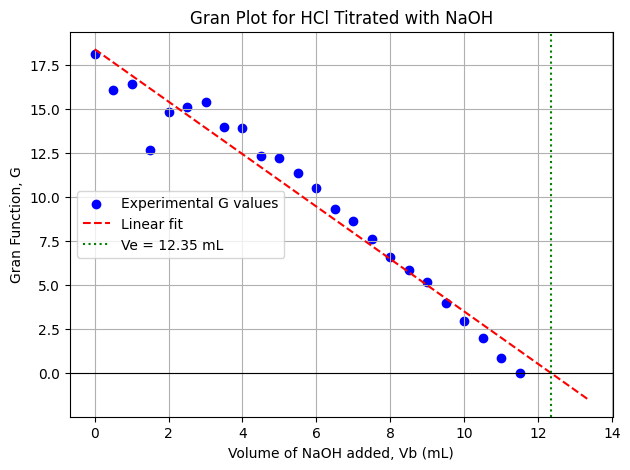

In [ ]:
# Step 1: Fit a straight line to the pre-equivalence G vs Vb data
slope, intercept = np.polyfit(Vb, G, 1)

# Step 2: Solve for Ve (x-intercept, where G = 0)
Ve = -intercept / slope
print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")
print(f"Equivalence Volume (Ve): {Ve:.2f} mL")

# Step 3: Calculate unknown acid concentration
Ca_calculated = (Cb * Ve) / V0
print(f"Calculated Acid Concentration (Ca): {Ca_calculated:.4f} M")

# Step 4: Plot the Gran plot
Vb_line = np.linspace(0, Ve + 1, 100)
G_line = slope * Vb_line + intercept

plt.figure(figsize=(7, 5))
plt.scatter(Vb, G, color="blue", label="Experimental G values")
plt.plot(Vb_line, G_line, color="red", linestyle="--", label="Linear fit")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(Ve, color="green", linestyle=":", label=f"Ve = {Ve:.2f} mL")
plt.xlabel("Volume of NaOH added, Vb (mL)")
plt.ylabel("Gran Function, G")
plt.title("Gran Plot for HCl Titrated with NaOH")
plt.legend()
plt.grid(True)

# Step 5: Save plot as JPEG
plt.savefig("gran_plot.jpg", format="jpg", dpi=300, bbox_inches="tight")
print("Plot saved as gran_plot.jpg")

plt.show()

Titration Data

 Vb1 (mL)  Vb2 (mL)  pH1   pH2  dpH/dV  Midpoint Vb (mL)
      0.0       0.5 0.14  0.20    0.12              0.25
      0.5       1.0 0.20  0.20    0.00              0.75
      1.0       1.5 0.20  0.32    0.24              1.25
      1.5       2.0 0.32  0.26   -0.12              1.75
      2.0       2.5 0.26  0.26    0.00              2.25
      2.5       3.0 0.26  0.26    0.00              2.75
      3.0       3.5 0.26  0.31    0.10              3.25
      3.5       4.0 0.31  0.32    0.02              3.75
      4.0       4.5 0.32  0.38    0.12              4.25
      4.5       5.0 0.38  0.39    0.02              4.75
      5.0       5.5 0.39  0.43    0.08              5.25
      5.5       6.0 0.43  0.47    0.08              5.75
      6.0       6.5 0.47  0.53    0.12              6.25
      6.5       7.0 0.53  0.57    0.08              6.75
      7.0       7.5 0.57  0.63    0.12              7.25
      7.5       8.0 0.63  0.70    0.14              7.75
      8.0       8.5 0.70  0.76 

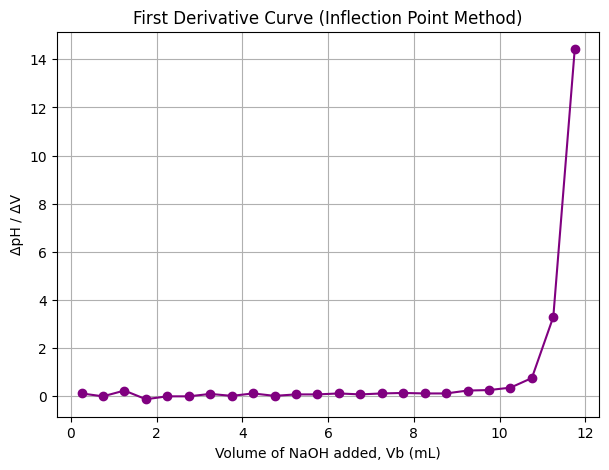

Approximate inflection point (Ve): 11.75 mL
Maximum slope (ΔpH/ΔV): 14.42


In [ ]:
# Full data including the point past equivalence (Vb = 12.00 mL, pH = 10.49)
Vb_full = np.append(Vb, 12.00)
pH_full = np.append(pH, 10.49)

# Sort to be safe
sort_index_full = np.argsort(Vb_full)
Vb_full = Vb_full[sort_index_full]
pH_full = pH_full[sort_index_full]

# First derivative calculation
dpH = np.diff(pH_full)
dV = np.diff(Vb_full)
derivative = dpH / dV

# Midpoint of each interval
midpoints = (Vb_full[:-1] + Vb_full[1:]) / 2

# Build derivative table
derivative_table = pd.DataFrame({
    "Vb1 (mL)": Vb_full[:-1],
    "Vb2 (mL)": Vb_full[1:],
    "pH1": pH_full[:-1],
    "pH2": pH_full[1:],
    "dpH/dV": derivative.round(2),
    "Midpoint Vb (mL)": midpoints
})
print(derivative_table.to_string(index=False))

# Export derivative table as JPEG
styled_derivative_table = derivative_table.style.set_caption("First Derivative (dpH/dV) Table")
dfi.export(styled_derivative_table, "derivative_table.jpg", table_conversion="matplotlib")
print("Table saved as derivative_table.jpg")

# Plot the derivative curve
plt.figure(figsize=(7, 5))
plt.plot(midpoints, derivative, marker="o", color="purple")
plt.xlabel("Volume of NaOH added, Vb (mL)")
plt.ylabel("ΔpH / ΔV")
plt.title("First Derivative Curve (Inflection Point Method)")
plt.grid(True)

# Save plot as JPEG
plt.savefig("derivative_plot.jpg", format="jpg", dpi=300, bbox_inches="tight")
print("Plot saved as derivative_plot.jpg")

plt.show()

# Identify the inflection point (maximum slope)
max_index = np.argmax(derivative)
print(f"Approximate inflection point (Ve): {midpoints[max_index]:.2f} mL")
print(f"Maximum slope (ΔpH/ΔV): {derivative[max_index]:.2f}")

In [ ]:
from google.colab import files
files.download("pre_equivalence_table.jpg")
files.download("gran_plot.jpg")
files.download("derivative_table.jpg")
files.download("derivative_plot.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>